# Problema 2 - Regressão Logística para previsão de doença cardíaca (UCI Heart Disease - base de Cleveland, 303 pacientes, 13 variáveis clínicas).


In [1]:
from pathlib import Path


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ----------------------------------------------------------------------------
# Configurações gerais
# ----------------------------------------------------------------------------
BASE = Path.cwd()  # abra o notebook DENTRO da pasta do problema (ao lado de dados/)
ARQ_DADOS = BASE / "dados" / "processed.cleveland.data"
PASTA_FIG = BASE / "figuras"
PASTA_FIG.mkdir(exist_ok=True)

SEED = 42

# O arquivo original não tem cabeçalho: os nomes vêm da documentação da UCI.
COLUNAS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target",
]
FEATURES = COLUNAS[:-1]  # as 13 variáveis clínicas
# Variáveis nominais com mais de 2 categorias (usadas só na análise complementar)
NOMINAIS = ["cp", "restecg", "slope", "thal"]


def titulo(texto):
    """Imprime um cabeçalho para separar as seções na saída do terminal."""
    print("\n" + "=" * 78)
    print(texto)
    print("=" * 78)


def metricas(y_real, y_prev, y_prob):
    """Calcula as métricas pedidas (classe positiva = 1 = com doença)."""
    return {
        "Acurácia": accuracy_score(y_real, y_prev),
        "Precisão": precision_score(y_real, y_prev),
        "Recall": recall_score(y_real, y_prev),
        "F1-score": f1_score(y_real, y_prev),
        "AUC": roc_auc_score(y_real, y_prob),
    }

# 0. CARREGAMENTO E INSPEÇÃO

In [3]:
titulo("0. Carregamento e inspeção dos dados")

# No arquivo da UCI, valores ausentes aparecem como "?"  ->  na_values="?"
df = pd.read_csv(ARQ_DADOS, header=None, names=COLUNAS, na_values="?")
print(f"Formato (linhas, colunas): {df.shape}  -> 13 variáveis + alvo")
print("\nPrimeiras linhas:")
print(df.head())

print("\nValores ausentes por coluna (apenas as que têm):")
ausentes = df.isna().sum()
print(ausentes[ausentes > 0])
print(f"Linhas com algum valor ausente: {df.isna().any(axis=1).sum()}")

print("\nDistribuição ORIGINAL do alvo (0 = sem doença; 1 a 4 = graus de doença):")
print(df["target"].value_counts().sort_index())

# ----------------------------------------------------------------------------
# Binarização do alvo: 0 -> 0 (sem doença); 1, 2, 3, 4 -> 1 (com doença)
# ----------------------------------------------------------------------------
df["target"] = (df["target"] > 0).astype(int)
print("\nDistribuição do alvo BINARIZADO (0 = sem doença, 1 = com doença):")
print(df["target"].value_counts().sort_index())
print(df["target"].value_counts(normalize=True).sort_index().round(3))

X = df[FEATURES]
y = df["target"]


0. Carregamento e inspeção dos dados
Formato (linhas, colunas): (303, 14)  -> 13 variáveis + alvo

Primeiras linhas:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Valores ausentes por coluna (apenas as que têm):
ca      4
thal    2
dtype: int64
Linhas com algum valor ausente: 6

Distribuição ORIGINAL do alvo (0 = sem doença; 1 a 4 = graus de doença):
target
0    164
1     55
2     36
3     35
4    

## PRÉ-PROCESSAMENTO: divisão treino/teste

* O enunciado não fixa a proporção; usamos 80% treino / 20% teste.  
* stratify=y mantém a proporção de doentes igual em treino e teste  
  (importante com poucas amostras: o teste tem só ~61 pacientes).  
* A divisão vem ANTES de imputar e padronizar: média, desvio e moda são  
  calculados só no treino (evita vazamento de dados / data leakage).

In [4]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f"\nTreino: {len(X_treino)} pacientes | doentes: {y_treino.mean():.1%}")
print(f"Teste : {len(X_teste)} pacientes | doentes: {y_teste.mean():.1%}")

# Tratamento de ausentes: 'ca' (4) e 'thal' (2) são variáveis de contagem/
# categoria, então usamos a MODA (valor mais frequente) calculada no treino.
imputador = SimpleImputer(strategy="most_frequent")
# Padronização z = (x - média) / desvio, ajustada no treino.
escalador = StandardScaler()

X_tr = escalador.fit_transform(imputador.fit_transform(X_treino))
X_te = escalador.transform(imputador.transform(X_teste))
print(f"\nValores ausentes imputados com a moda do treino: "
      f"{dict(zip(FEATURES, imputador.statistics_))['ca']:.0f} (ca) e "
      f"{dict(zip(FEATURES, imputador.statistics_))['thal']:.0f} (thal)")


Treino: 242 pacientes | doentes: 45.9%
Teste : 61 pacientes | doentes: 45.9%

Valores ausentes imputados com a moda do treino: 0 (ca) e 3 (thal)


## TAREFA 1 - Treinar LogisticRegression e informar as iterações até convergir

In [8]:
titulo("TAREFA 1 - Treinamento da Regressão Logística")

# Parâmetros EXATOS pedidos no enunciado.
modelo = LogisticRegression(solver="liblinear", random_state=SEED, max_iter=1000)
modelo.fit(X_tr, y_treino)

# n_iter_ : número de iterações que o otimizador executou até convergir.
# No solver 'liblinear' ele vem como array de 1 posição (problema binário).
n_iter = int(modelo.n_iter_[0])
print(f"Iterações até a convergência (n_iter_): {n_iter}")
print(f"Limite configurado (max_iter)          : 1000")
print(f"Convergiu antes do limite?              {'SIM' if n_iter < 1000 else 'NÃO'}")
print("\nRegularização padrão do scikit-learn: L2 com C = 1.0 (não alterada).")

# Coeficientes na escala padronizada: comparáveis entre si.
# exp(coef) = razão de chances (odds ratio) para +1 desvio padrão da variável.
tab_coef = pd.DataFrame(
    {
        "coeficiente": modelo.coef_[0],
        "odds_ratio_por_1DP": np.exp(modelo.coef_[0]),
    },
    index=FEATURES,
).sort_values("coeficiente", key=np.abs, ascending=False)
print(f"\nIntercepto: {modelo.intercept_[0]:+.4f}")
print("\nCoeficientes (variáveis padronizadas), ordenados por |coeficiente|:")
print(tab_coef.round(4))


TAREFA 1 - Treinamento da Regressão Logística
Iterações até a convergência (n_iter_): 5
Limite configurado (max_iter)          : 1000
Convergiu antes do limite?              SIM

Regularização padrão do scikit-learn: L2 com C = 1.0 (não alterada).

Intercepto: -0.0782

Coeficientes (variáveis padronizadas), ordenados por |coeficiente|:
          coeficiente  odds_ratio_por_1DP
ca             1.1085              3.0299
thal           0.6784              1.9707
sex            0.6557              1.9265
cp             0.5433              1.7216
exang          0.3838              1.4679
slope          0.3541              1.4248
thalach       -0.3484              0.7058
trestbps       0.3136              1.3683
fbs           -0.2205              0.8021
restecg        0.2175              1.2430
chol           0.2154              1.2404
oldpeak        0.1497              1.1615
age           -0.1035              0.9017


## TAREFA 2 - Avaliação no conjunto de teste

In [9]:
titulo("TAREFA 2 - Avaliação no conjunto de teste")

# predict_proba -> probabilidade da classe 1 (com doença).
# predict       -> classe, usando o limiar padrão de 0,5.
prob_teste = modelo.predict_proba(X_te)[:, 1]
prev_teste = modelo.predict(X_te)

res = metricas(y_teste, prev_teste, prob_teste)
print("Métricas no teste (limiar = 0,5; classe positiva = com doença):")
for nome, valor in res.items():
    print(f"  {nome:9s}: {valor:.4f}")

cm = confusion_matrix(y_teste, prev_teste)
vn, fp, fn, vp = cm.ravel()
print("\nMatriz de confusão (linhas = real, colunas = previsto):")
print(pd.DataFrame(cm, index=["Real: sem doença", "Real: com doença"],
                   columns=["Prev: sem doença", "Prev: com doença"]))
print(f"\nVP = {vp} | VN = {vn} | FP = {fp} | FN = {fn}")
print(f"Um único erro altera a acurácia em {1 / len(y_teste):.1%} (teste pequeno).")

# Conferência manual das fórmulas dos slides (Métricas de Avaliação)
assert np.isclose(res["Acurácia"], (vp + vn) / (vp + vn + fp + fn))
assert np.isclose(res["Precisão"], vp / (vp + fp))
assert np.isclose(res["Recall"], vp / (vp + fn))
assert np.isclose(res["F1-score"], 2 * res["Precisão"] * res["Recall"] / (res["Precisão"] + res["Recall"]))


TAREFA 2 - Avaliação no conjunto de teste
Métricas no teste (limiar = 0,5; classe positiva = com doença):
  Acurácia : 0.8689
  Precisão : 0.8125
  Recall   : 0.9286
  F1-score : 0.8667
  AUC      : 0.9513

Matriz de confusão (linhas = real, colunas = previsto):
                  Prev: sem doença  Prev: com doença
Real: sem doença                27                 6
Real: com doença                 2                26

VP = 26 | VN = 27 | FP = 6 | FN = 2
Um único erro altera a acurácia em 1.6% (teste pequeno).



AUC-ROC: 0.9513


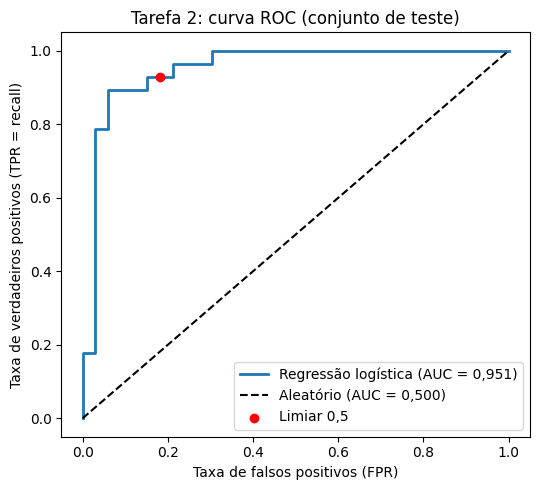

In [10]:
# --- Curva ROC e AUC --------------------------------------------------------
fpr, tpr, limiares = roc_curve(y_teste, prob_teste)
auc = roc_auc_score(y_teste, prob_teste)
print(f"\nAUC-ROC: {auc:.4f}")

# Ponto de operação do limiar 0,5 sobre a curva
fpr_05 = fp / (fp + vn)
tpr_05 = vp / (vp + fn)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, lw=2, label="Regressão logística (AUC = " + f"{auc:.3f}".replace(".", ",") + ")")
ax.plot([0, 1], [0, 1], "k--", label="Aleatório (AUC = 0,500)")
ax.scatter([fpr_05], [tpr_05], color="red", zorder=5, label="Limiar 0,5")
ax.set_xlabel("Taxa de falsos positivos (FPR)")
ax.set_ylabel("Taxa de verdadeiros positivos (TPR = recall)")
ax.set_title("Tarefa 2: curva ROC (conjunto de teste)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t2_curva_roc.png", dpi=150)
plt.show()

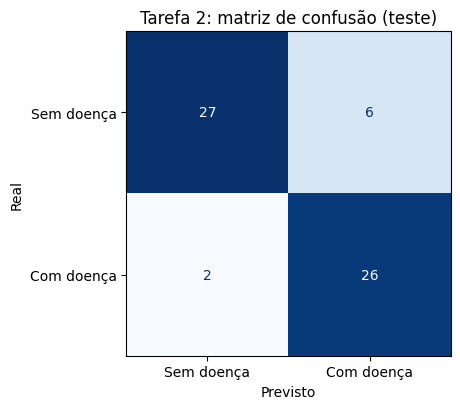

In [11]:
# --- Figura: matriz de confusão ---------------------------------------------
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["Sem doença", "Com doença"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Tarefa 2: matriz de confusão (teste)")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t2_matriz_confusao.png", dpi=150)
plt.show()

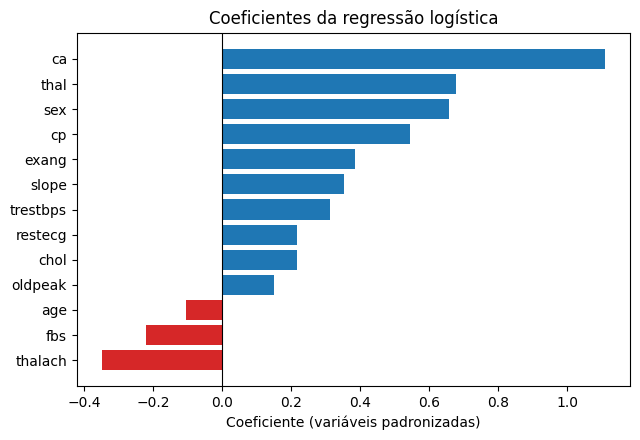

In [8]:
# --- Figura: coeficientes ---------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ordem = tab_coef.sort_values("coeficiente")
ax.barh(ordem.index, ordem["coeficiente"],
        color=["tab:red" if v < 0 else "tab:blue" for v in ordem["coeficiente"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coeficiente (variáveis padronizadas)")
ax.set_title("Coeficientes da regressão logística")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t2_coeficientes.png", dpi=150)
plt.show()

# ANÁLISES COMPLEMENTARES 

# C1. Validação cruzada estratificada (5 folds) só no treino 
# O teste tem só 61 pacientes: o resultado de uma única divisão é incerto.
# A validação cruzada dá uma ideia da variabilidade. O Pipeline refaz a
# imputação e a padronização dentro de cada fold (sem vazamento).


In [12]:
titulo("COMPLEMENTAR C1 - Validação cruzada 5-fold estratificada (apenas treino)")

pipe_base = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(solver="liblinear", random_state=SEED, max_iter=1000)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"Acurácia": "accuracy", "Precisão": "precision", "Recall": "recall",
           "F1-score": "f1", "AUC": "roc_auc"}
cv_res = cross_validate(pipe_base, X_treino, y_treino, cv=cv, scoring=scoring)
tab_cv = pd.DataFrame(
    {nome: [cv_res[f"test_{nome}"].mean(), cv_res[f"test_{nome}"].std()] for nome in scoring},
    index=["média", "desvio padrão"],
).T
print(tab_cv.round(4))


COMPLEMENTAR C1 - Validação cruzada 5-fold estratificada (apenas treino)
           média  desvio padrão
Acurácia  0.8264         0.0172
Precisão  0.8441         0.0337
Recall    0.7652         0.0547
F1-score  0.8007         0.0260
AUC       0.8960         0.0148


#  C2. Variante: one-hot para variáveis nominais 
# cp (1-4), restecg (0-2), slope (1-3) e thal (3, 6, 7) são códigos de
# categorias, sem ordem numérica real. A versão principal (acima) as trata
# como números, como pede o enunciado ("padronização das variáveis
# independentes"). Aqui comparamos com a codificação one-hot dessas 4 variáveis.


In [13]:
titulo("COMPLEMENTAR C2 - Variante com one-hot nas variáveis nominais")

numericas = [c for c in FEATURES if c not in NOMINAIS]
pre_onehot = ColumnTransformer([
    # nominais: imputa pela moda e vira dummies
    ("nom", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), NOMINAIS),
    # numéricas/binárias: imputa pela moda e padroniza
    ("num", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("sc", StandardScaler())]), numericas),
])
pipe_oh = Pipeline([
    ("pre", pre_onehot),
    ("modelo", LogisticRegression(solver="liblinear", random_state=SEED, max_iter=1000)),
])
pipe_oh.fit(X_treino, y_treino)
prob_oh = pipe_oh.predict_proba(X_teste)[:, 1]
prev_oh = pipe_oh.predict(X_teste)
res_oh = metricas(y_teste, prev_oh, prob_oh)
n_iter_oh = int(pipe_oh.named_steps["modelo"].n_iter_[0])
print(f"Iterações até convergir: {n_iter_oh}")
for nome, valor in res_oh.items():
    print(f"  {nome:9s}: {valor:.4f}")


COMPLEMENTAR C2 - Variante com one-hot nas variáveis nominais
Iterações até convergir: 6
  Acurácia : 0.8689
  Precisão : 0.8125
  Recall   : 0.9286
  F1-score : 0.8667
  AUC      : 0.9578


#  C3. Efeito do limiar de decisão (apenas ilustrativo) 
# Em triagem médica, um falso negativo (doente não detectado) é mais grave que
# um falso positivo. Baixar o limiar aumenta o recall e reduz a precisão.
# ATENÇÃO: a tabela abaixo usa o teste só para ILUSTRAR o compromisso; o
# limiar de um modelo real deve ser escolhido com dados de validação.


In [14]:
titulo("COMPLEMENTAR C3 - Efeito do limiar de decisão no teste (ilustrativo)")

linhas = []
for t in (0.3, 0.4, 0.5, 0.6, 0.7):
    p = (prob_teste >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_teste, p).ravel()
    linhas.append({
        "limiar": t,
        "Acurácia": accuracy_score(y_teste, p),
        "Precisão": precision_score(y_teste, p),
        "Recall": recall_score(y_teste, p),
        "FP": fp_,
        "FN": fn_,
    })
print(pd.DataFrame(linhas).set_index("limiar").round(3))


COMPLEMENTAR C3 - Efeito do limiar de decisão no teste (ilustrativo)
        Acurácia  Precisão  Recall  FP  FN
limiar                                    
0.3        0.803     0.700   1.000  12   0
0.4        0.869     0.812   0.929   6   2
0.5        0.869     0.812   0.929   6   2
0.6        0.869     0.833   0.893   5   3
0.7        0.902     0.893   0.893   3   3
